# Choosing your CRM

Pywaterflood exposes three independent choices: primary production, time-constant
layout, and gain constraints. Pick them from the data you actually have, then train
long enough that both the rate match and the physics residual improve.

Literature names (Wanderley de Holanda et al., 2018):

| This API | Name | What it fits |
|---|---|---|
| `tau_selection="per-pair"` | CRM-IP | $f_{ij}$ and $\tau_{ij}$ for every pair |
| `tau_selection="per-producer"` | CRM-P | $f_{ij}$ plus one $\tau_j$ per producer |
| summed field rates | CRM-T | one tank for the whole flood |


In [1]:
from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pywaterflood import CRM, CrmCompensated


from pathlib import Path

import pandas as pd


def load_sample_rates():
    """Load the 4-producer / 5-injector sample (local clone or GitHub)."""
    for folder in (Path("../../testing/data"), Path("testing/data")):
        if (folder / "production.csv").exists():
            root = folder
            prod = pd.read_csv(root / "production.csv", header=None)
            inj = pd.read_csv(root / "injection.csv", header=None)
            time = pd.read_csv(root / "time.csv", header=None)
            return prod, inj, time
    gh = "https://raw.githubusercontent.com/frank1010111/pywaterflood/master/testing/data/"
    prod = pd.read_csv(gh + "production.csv", header=None)
    inj = pd.read_csv(gh + "injection.csv", header=None)
    time = pd.read_csv(gh + "time.csv", header=None)
    return prod, inj, time


## Look at the rates first

Three questions decide the model:

1. Do rates rise with fill-up, or is there still decline when injection is quiet?
   That is `primary`.
2. Do injectors move independently (good for CRM-IP) or in lockstep (CRM-P may be enough)?
3. Does field production exceed field injection for long periods? That is aquifer
   support — add a pseudo-injector (see the aquifer notebook) and keep `"up-to one"`.


298 steps, 4 producers, 5 injectors
production / injection ratio: 0.9992753194861895


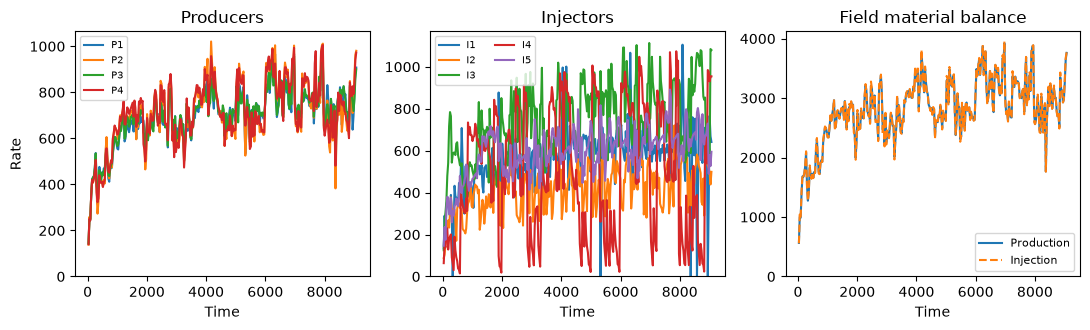

In [2]:
prod, inj, time = load_sample_rates()
t = time.to_numpy()[:, 0]
q = prod.to_numpy()
i = inj.to_numpy()
producer_ids = [f"P{k+1}" for k in range(q.shape[1])]
injector_ids = [f"I{k+1}" for k in range(i.shape[1])]
n_threads = max(1, min(os.cpu_count() or 1, q.shape[1]))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for k, name in enumerate(producer_ids):
    axes[0].plot(t, q[:, k], label=name)
for k, name in enumerate(injector_ids):
    axes[1].plot(t, i[:, k], label=name)
axes[2].plot(t, q.sum(axis=1), label="Production")
axes[2].plot(t, i.sum(axis=1), ls="--", label="Injection")
axes[0].set(title="Producers", xlabel="Time", ylabel="Rate", ylim=(0, None))
axes[1].set(title="Injectors", xlabel="Time", ylim=(0, None))
axes[2].set(title="Field material balance", xlabel="Time", ylim=(0, None))
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7, ncol=2)
axes[2].legend(fontsize=8)
fig.tight_layout()
print(len(t), "steps,", q.shape[1], "producers,", i.shape[1], "injectors")
print("production / injection ratio:", float(q.sum() / i.sum()))


This sample is a young waterflood: rates start low and climb, injectors are not
in phase, and field injection tracks production. That is enough data for CRM-IP
with `"up-to one"`. `primary=True` is still the safe default (it can go to a
small gain if depletion is absent).

On a real field, convert stock-tank barrels to reservoir barrels before this plot.


## CRM-IP (per-pair) — start here

One $\tau_{ij}$ per pipe. Highest resolution, most parameters. Use this unless
the history is short or the well count is large relative to the number of months.


/Users/rohit/pywaterflood/python/pywaterflood/crm.py:1347: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  t_obs = torch.as_tensor(time, dtype=_DTYPE, device=device)


CRM-IP RMSE [31.39 38.24 28.44 35.05] gains (4, 5) tau (4, 5)


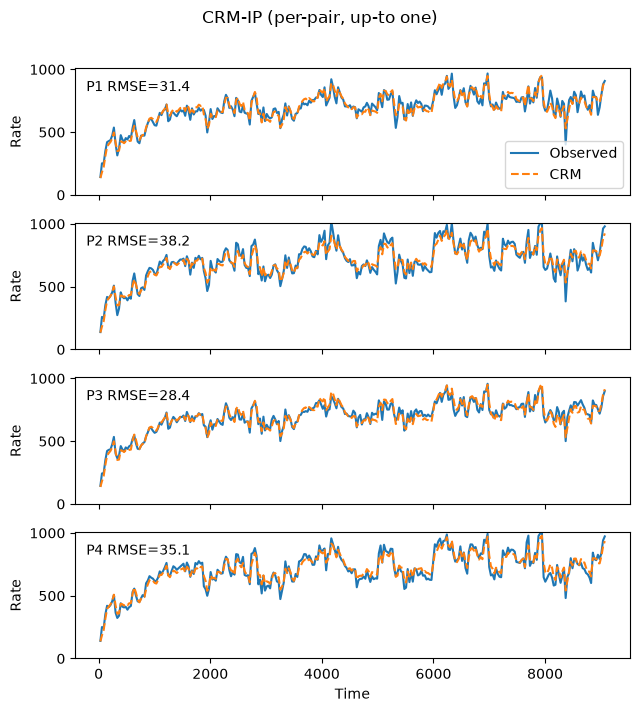

In [3]:
def fit_and_plot(model, title, **fit_kw):
    model.fit(q, i, t, num_cores=n_threads, **fit_kw)
    q_hat = model.predict()
    rmse = np.sqrt(np.mean((q - q_hat) ** 2, axis=0))
    fig, axes = plt.subplots(len(producer_ids), figsize=(6.5, 7), sharex=True, sharey=True)
    for k, name in enumerate(producer_ids):
        axes[k].plot(t, q[:, k], label="Observed")
        axes[k].plot(t, q_hat[:, k], ls="--", label="CRM")
        axes[k].set(ylabel="Rate", ylim=(0, None))
        axes[k].text(0.02, 0.82, f"{name} RMSE={rmse[k]:.1f}", transform=axes[k].transAxes)
    axes[0].legend(loc="lower right")
    axes[-1].set(xlabel="Time")
    fig.suptitle(title, y=1.01)
    fig.tight_layout()
    return model, rmse


crm_ip, rmse_ip = fit_and_plot(
    CRM(primary=True, tau_selection="per-pair", constraints="up-to one"),
    "CRM-IP (per-pair, up-to one)",
    epochs=200,
    seed=0,
)
print("CRM-IP RMSE", np.round(rmse_ip, 2), "gains", crm_ip.gains.shape, "tau", crm_ip.tau.shape)


## CRM-P (per-producer) — fewer parameters

One $\tau_j$ shared by every injector that supports producer $j$. Faster, more
stable on short or noisy history. Drop to this when CRM-IP gains jump between
random seeds or the next-year forecast is worse than the training match.


CRM-P RMSE [31.37 38.2  28.43 35.02] tau (4, 1)


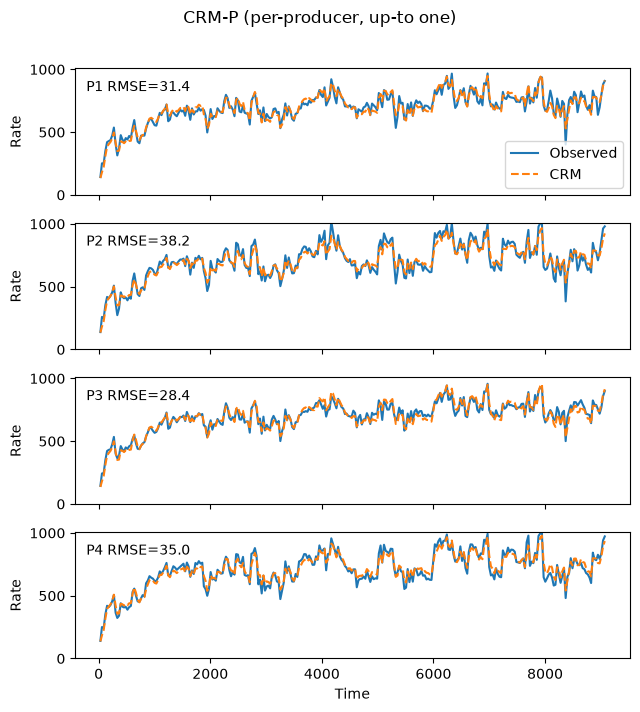

In [4]:
crm_p, rmse_p = fit_and_plot(
    CRM(primary=True, tau_selection="per-producer", constraints="up-to one"),
    "CRM-P (per-producer, up-to one)",
    epochs=200,
    seed=0,
)
print("CRM-P RMSE", np.round(rmse_p, 2), "tau", crm_p.tau.shape)


## CRM-T — field tank only

Sum every producer and every injector. This matches the field total and says
nothing about well pairs. Use it as a material-balance check, not as a
connectivity tool.


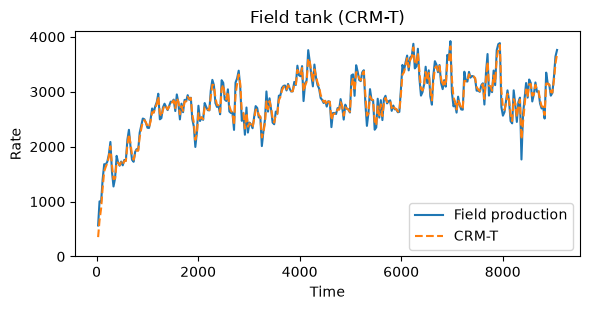

In [5]:
crm_t = CRM(primary=False, tau_selection="per-pair", constraints="up-to one")
crm_t.fit(q.sum(axis=1, keepdims=True), i.sum(axis=1, keepdims=True), t, epochs=150, seed=0)
q_t = crm_t.predict()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(t, q.sum(axis=1), label="Field production")
ax.plot(t, q_t[:, 0], ls="--", label="CRM-T")
ax.set(xlabel="Time", ylabel="Rate", ylim=(0, None), title="Field tank (CRM-T)")
ax.legend()
fig.tight_layout()


## Gain constraints

| `constraints` | Rule | When |
|---|---|---|
| `"up-to one"` | each injector column sums to $\le 1$ | default; some injection can be lost |
| `"sum-to-one"` | each producer row sums to 1 | every barrel a producer makes is from these injectors |
| `"positive"` | $f_{ij} \ge 0$ only | exploratory; easy to over-allocate injection |

`"up-to one"` is injector material balance. `"sum-to-one"` is a producer-side
partition. They are different statements. `"sum-to-one injector"` is not implemented.


In [6]:
rows = []
for name, kwargs in [
    ("up-to one", {"constraints": "up-to one"}),
    ("sum-to-one", {"constraints": "sum-to-one"}),
    ("positive", {"constraints": "positive"}),
]:
    m = CRM(primary=True, tau_selection="per-producer", **kwargs)
    m.fit(q, i, t, epochs=120, seed=0, num_cores=n_threads)
    g = m.gains
    rows.append(
        {
            "constraints": name,
            "min f": g.min(),
            "max f": g.max(),
            "max injector sum": g.sum(axis=0).max(),
            "max producer sum": g.sum(axis=1).max(),
            "RMSE": float(np.sqrt(np.mean((q - m.predict()) ** 2))),
        }
    )
pd.DataFrame(rows).round(3)


,constraints,min f,max f,max injector sum,max producer sum,RMSE
0,up-to one,0.245,0.255,1.000,1.270,33.765
1,sum-to-one,0.079,0.468,1.828,1.000,98.491
2,positive,0.129,0.303,1.192,1.233,50.468


## PINN knobs that change the answer

`fit()` trains rate networks plus the physical parameter head. Useful arguments:

| Argument | Default | Use |
|---|---|---|
| `epochs` / `options={"maxiter": N}` | 2000 | training steps |
| `lr` | 1e-3 | step size (parameter head uses $5\times$) |
| `physics_weight` | 1 | raise if rates match and the ODE residual does not |
| `initial_guess` | uniform | `"geometry"` with a well map; `"random"` for restarts |
| `seed` | 0 | repeatable network init |
| `device` | CPU | `"cuda"` if present; MPS falls back to CPU |

Several random restarts (`random=True`, different `seed`) and a hold-out of the
last months of rates are how you decide the model is usable, not the training RMSE
alone.


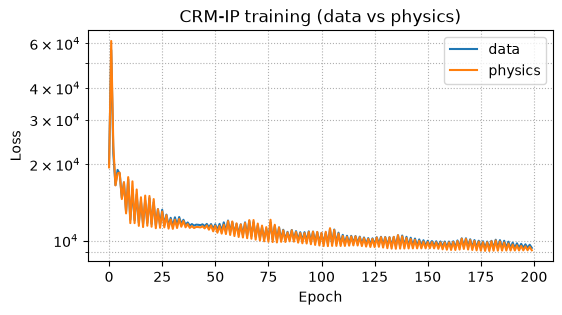

In [7]:
hist = pd.DataFrame(crm_ip.loss_history_)
ax = hist[["data", "physics"]].plot(figsize=(6, 3), logy=True)
ax.set(xlabel="Epoch", ylabel="Loss", title="CRM-IP training (data vs physics)")
ax.grid(True, which="both", ls=":")


## Pressure-compensated CRM

When producer BHP is known, use `CrmCompensated`. A workover or choke change
then has a pressure term instead of a fake new injector connection.


In [8]:
pressure = 1000.0 - 0.1 * q  # replace with measured BHP
crm_bhp = CrmCompensated(primary=True, tau_selection="per-pair", constraints="up-to one")
crm_bhp.fit(q, pressure, i, t, epochs=120, seed=0, num_cores=n_threads)
print("CrmCompensated RMSE", float(np.sqrt(np.mean((q - crm_bhp.predict()) ** 2))))
print("productivity index J", np.round(crm_bhp.productivity_index, 4))


CrmCompensated RMSE 37.875314525137334
productivity index J [0.9979 0.9991 0.9999 0.9963]


## Decision order

1. Clean rates into `(n_time, n_wells)`, reservoir barrels, no NaNs.
2. Plot field production vs injection. Persistent surplus production → aquifer
   pseudo-well (aquifer notebook).
3. Start with `CRM(primary=True, tau_selection="per-pair", constraints="up-to one")`.
4. If you have a well map, `initial_guess="geometry"` (MPI notebook).
5. If you have BHP, refit `CrmCompensated`.
6. If pair gains are unstable, drop to `tau_selection="per-producer"`.
7. Forecast with concatenated history + plan in `predict()`.
8. Keep the restart whose **held-out** months match, then export `gains`.

CRM-Block (delayed blocks along a pair) is not in this package. Perforation-level
ML-CRM is CRM-IP on allocated layer rates — same class, finer columns.
